# S2 · Systemic financial crisis: choosing the variables before building any data

**Where this stands.** No analysis dataset is built yet, but the open source data are now downloaded and decoded into two tables (`data/processed/s2_country_year_inputs.csv`, `data/processed/s2_bailout_programmes.csv`, made by `src/prepare_s2_sources.py`). This notebook (1) says what S2 is, (2) lists the candidate **input, output and control variables** and what the repository already holds, (3) checks the data we have, and (4) proposes what to fix before a dataset is built. The goal is to avoid the problems S1 ran into: no measure of how big the shock was, too few cases, and many tests on a small sample.

**The shock.** In the Scope Review, S2 is a *systemic financial crisis*, with the euro-area crisis of 2008–2013 as the reference episode (Spain, Greece, Portugal, Ireland; the deck also names Italy). The question is the same as for S1: after the shock, how do trust, turnout, the party system and the radical vote move?

**What is different from S1.** A government falling is a political event whose size we could not measure. A financial crisis is an **economic shock that can be measured in numbers** (unemployment, output, debt, bailouts) and it hit **every European country, to very different degrees**. That is the opportunity: instead of 4 cases we may have about 27 countries, each with its own severity.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from trust_windows import EU27, ISO3_TO_EB, load_waves

pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)
BLUE, RED, GREY, LIGHT = '#245f91', '#c45d3f', '#8a98a6', '#d9e2ea'
EB_TO_ISO3 = {v: k for k, v in ISO3_TO_EB.items()}
NAME = {'AT': 'Austria', 'BE': 'Belgium', 'BG': 'Bulgaria', 'CY': 'Cyprus', 'CZ': 'Czechia', 'DE': 'Germany', 'DK': 'Denmark',
        'EE': 'Estonia', 'EL': 'Greece', 'ES': 'Spain', 'FI': 'Finland', 'FR': 'France', 'HR': 'Croatia', 'HU': 'Hungary',
        'IE': 'Ireland', 'IT': 'Italy', 'LT': 'Lithuania', 'LU': 'Luxembourg', 'LV': 'Latvia', 'MT': 'Malta', 'NL': 'Netherlands',
        'PL': 'Poland', 'PT': 'Portugal', 'RO': 'Romania', 'SE': 'Sweden', 'SI': 'Slovenia', 'SK': 'Slovakia'}
REFERENCE = ['ES', 'EL', 'PT', 'IE']   # the four S2 episodes in data/raw/shocks/episodes.csv
DECK = REFERENCE + ['IT']              # the deck also names Italy

macro = pd.read_csv(ROOT / 'data/processed/eurostat_macro_country_year.csv')
episodes = pd.read_csv(ROOT / 'data/raw/shocks/episodes.csv')
eb = load_waves()
print('Reference S2 episodes in episodes.csv:', ', '.join(episodes[episodes.shock == 'S2'].country))
print(f'Eurostat table: {macro.geo.nunique()} geographies, {int(macro.year.min())}-{int(macro.year.max())}. Eurobarometer: {eb.country_code.nunique()} codes, {eb.wave.nunique()} waves.')

Reference S2 episodes in episodes.csv: Spain, Greece, Portugal, Ireland
Eurostat table: 51 geographies, 2000-2025. Eurobarometer: 32 codes, 48 waves.


## 1. What S1 taught us

| Lesson from S1 | What it means for S2 |
| --- | --- |
| There was **no input that measured how big the shock was**, so "mild, central, severe" could not be built. | S2 can have one. Severity comes from economic data that are **not themselves a political outcome**: unemployment, output, debt, bailouts. |
| **Too few cases** (8 to 19) and many of them from the same country. | Use **all EU countries**, each with its own severity, not just the four reference episodes. |
| Each case was compared with other countries, which needs a clean comparison group. | In S2 almost every country was hit, so there is **no untouched comparison group**. The comparison is **more hit against less hit**, plus time effects for EU-wide movements. |
| We tried **13 variables on 19 cases** and one looked good by luck. | **Decide the main severity measure, the outcomes and the windows before looking**, and count every test. |
| Approximate dates, long gaps to the next election, and twice-yearly surveys blurred the timing. | Fix the **windows in advance**: one baseline before the crisis, follow-ups at set years. Treat elections separately because they come on their own calendar. |
| Classification changes (Belgium's N-VA) and renamed party lists produced false jumps in the radical vote. | Keep the **party classification constant** and check any vote series against a second source. |

## 2. Candidate variables

**Inputs** describe the shock and must be measured **independently of the political outcomes**. **Outputs** are what we want to describe. **Controls** are things that could otherwise be mistaken for the effect of the crisis.

*In the repo?* means a table already exists in `data/`. *Main issue* is what could go wrong.

In [2]:
rows = [
 # role, variable, what it measures, source, in repo, main issue
 ('Input', 'Unemployment rise', 'Unemployment peak (2008-2014) minus 2007, percentage points', 'Eurostat', 'Yes', 'Main severity measure in the literature (Algan et al. 2017). Peaks at different dates'),
 ('Input', 'Output loss', 'Real GDP from 2007 to its trough, %', 'Eurostat', 'Growth rates only', 'Built here from growth rates; GDP levels are now downloaded (section 5b) and cleaner'),
 ('Input', 'Public debt jump', 'Debt/GDP in 2013 minus 2007, percentage points', 'Eurostat', 'Yes', 'Mixes bank rescues, falling GDP and deficits'),
 ('Input', 'Systemic banking crisis and its cost', 'Whether and when a banking crisis began, fiscal cost, output loss', 'IMF (Laeven & Valencia)', 'No', 'The financial side of the shock; needs a download and a country mapping'),
 ('Input', 'Bailout programme', 'Whether, when and how large an IMF/EU programme was (Greece, Ireland, Portugal, Cyprus, bank programme for Spain)', 'ESM/EFSF file (team), European Commission and IMF pages', 'Yes (8 countries)', 'Lower bound: bilateral loans to Ireland and the Nordic loans to Latvia are agreed but not found as paid. IMF euro amounts are converted from SDR'),
 ('Input', 'Sovereign stress', '10-year government bond yield, spread over Germany', 'Eurostat (irt_lt_mcby_a)', 'Yes (downloaded)', 'No Estonian series; the spread over Germany is easy to compute'),
 ('Input', 'Fiscal tightening', 'Change in the deficit or structural balance after 2009', 'Eurostat (gov_10dd_edpt1)', 'Yes (deficit downloaded)', 'Austerity is the political channel in much of the literature; structural balance is not downloaded'),
 ('Input', 'Youth unemployment, house prices, bank loans in trouble', 'Extra measures of how deep the hit went', 'Eurostat, World Bank', 'Yes (downloaded)', 'Youth unemployment complete; house prices 19 of 27 countries; bank loans in trouble only 9 of 27 complete. Each adds a test'),
 ('Output', 'Trust in parliament, government, parties', 'Share who "tend to trust", twice a year', 'Eurobarometer', 'Yes (2005-2026)', 'Coarse timing and about 3 points of sampling noise per country'),
 ('Output', 'Satisfaction with democracy', 'Mean on a 0 to 10 scale, every two years', 'ESS', 'Yes (country-round table)', 'Biennial; a different scale from Eurobarometer'),
 ('Output', 'Radical vote (far right, far left)', 'Vote share of parties PopuList classes as such', 'PopuList + PPEG, checked with ParlGov', 'Yes (all EU27)', 'Elections come on their own calendar; links unchecked by a person'),
 ('Output', 'Populist / anti-establishment vote', 'Vote share of parties PopuList classes as populist', 'PopuList + PPEG', 'Not yet computed', 'The measure used by Algan et al.; broader than far right or far left'),
 ('Output', 'Turnout, effective number of parties', 'At the first election after the crisis began', 'PPEG, IDEA', 'Yes', 'Compulsory voting must be left out of turnout'),
 ('Output', 'Government turnover, incumbent vote loss', 'Whether the government changed, how much its parties lost', 'PPEG', 'Partly (cabinets yes, incumbent loss not built)', 'Needs a rule for who the incumbent is'),
 ('Output', 'Trust in European institutions', 'Share who tend to trust the European Parliament, Commission, ECB and European Council', 'Eurobarometer (STD105 volume D, tables QA12.1 to QA12.4)', 'Raw only', 'The tables are in the repo but not processed; relevant because the crisis was a euro crisis'),
 ('Control', 'Trust before the crisis', 'Average trust in 2006-2007', 'Eurobarometer', 'Yes', 'Low starting trust limits how far it can fall'),
 ('Control', 'Radical or populist vote before the crisis', 'At the last election before 2008', 'PopuList + PPEG', 'Yes', 'Strong parties may grow faster or have less room'),
 ('Control', 'Euro membership and EU accession year', 'In the euro area by 2008, post-communist or not', 'Hand-made', 'No', 'Euro members could not devalue; accession countries start with lower trust'),
 ('Control', 'Income level and debt before the crisis', 'GDP per head and debt/GDP in 2007', 'Eurostat', 'Yes (income downloaded)', 'Rich and poor countries start from different places'),
 ('Control', 'Election timing', 'Where each country sat in its election cycle', 'PPEG', 'Yes', 'An election just before or after the shock changes what is observed'),
 ('Control', 'Compulsory voting, electoral system', 'Legal rule, proportional or majoritarian', 'IDEA, hand-made', 'Compulsory voting yes', 'Affects turnout and the number of parties'),
 ('Control', 'Corruption and institutional quality', 'V-Dem indices', 'V-Dem (full file in the zip)', 'Only two indices extracted', 'Corruption scandals during the crisis are a separate shock (S3)'),
 ('Control', 'Other shocks in the window', 'Government collapses (S1), scandals, the 2015 migration surge', 'PPEG, review table', 'Partly', 'Keeps the window to 2008-2014 and flags overlaps'),
]
plan = pd.DataFrame(rows, columns=['Role', 'Variable', 'What it measures', 'Source', 'In the repo?', 'Main issue'])
inrepo = plan['In the repo?'].str.startswith('Yes')
print(plan.groupby('Role').size().to_dict(), '| already in the repo:', int(inrepo.sum()), 'of', len(plan))
plan.style.hide(axis='index').set_properties(**{'text-align': 'left'})

{'Control': 8, 'Input': 8, 'Output': 7} | already in the repo: 14 of 23


Role,Variable,What it measures,Source,In the repo?,Main issue
Input,Unemployment rise,"Unemployment peak (2008-2014) minus 2007, percentage points",Eurostat,Yes,Main severity measure in the literature (Algan et al. 2017). Peaks at different dates
Input,Output loss,"Real GDP from 2007 to its trough, %",Eurostat,Growth rates only,Built here from growth rates; GDP levels are now downloaded (section 5b) and cleaner
Input,Public debt jump,"Debt/GDP in 2013 minus 2007, percentage points",Eurostat,Yes,"Mixes bank rescues, falling GDP and deficits"
Input,Systemic banking crisis and its cost,"Whether and when a banking crisis began, fiscal cost, output loss",IMF (Laeven & Valencia),No,The financial side of the shock; needs a download and a country mapping
Input,Bailout programme,"Whether, when and how large an IMF/EU programme was (Greece, Ireland, Portugal, Cyprus, bank programme for Spain)","ESM/EFSF file (team), European Commission and IMF pages",Yes (8 countries),Lower bound: bilateral loans to Ireland and the Nordic loans to Latvia are agreed but not found as paid. IMF euro amounts are converted from SDR
Input,Sovereign stress,"10-year government bond yield, spread over Germany",Eurostat (irt_lt_mcby_a),Yes (downloaded),No Estonian series; the spread over Germany is easy to compute
Input,Fiscal tightening,Change in the deficit or structural balance after 2009,Eurostat (gov_10dd_edpt1),Yes (deficit downloaded),Austerity is the political channel in much of the literature; structural balance is not downloaded
Input,"Youth unemployment, house prices, bank loans in trouble",Extra measures of how deep the hit went,"Eurostat, World Bank",Yes (downloaded),Youth unemployment complete; house prices 19 of 27 countries; bank loans in trouble only 9 of 27 complete. Each adds a test
Output,"Trust in parliament, government, parties","Share who ""tend to trust"", twice a year",Eurobarometer,Yes (2005-2026),Coarse timing and about 3 points of sampling noise per country
Output,Satisfaction with democracy,"Mean on a 0 to 10 scale, every two years",ESS,Yes (country-round table),Biennial; a different scale from Eurobarometer


**Reading the table.** Most severity inputs are now in the repo (unemployment, output, debt, deficit, bond yields, youth unemployment, bailout loans from ESM/EFSF). The **banking-crisis dates and costs** (Laeven and Valencia) are still missing. The outputs are mostly available. Trust in European institutions is in the raw Eurobarometer files and only needs processing; a satisfaction-with-democracy series that comes twice a year is the main output we would have to find.

## 3. Does the severity vary, and who was hit?

Three severity measures from the Eurostat data in the repo, for every EU country: the rise in unemployment (2007 to its peak), the loss of output (2007 to its trough) and the jump in public debt (2007 to 2013). The four S2 reference episodes are in red, Italy in grey.

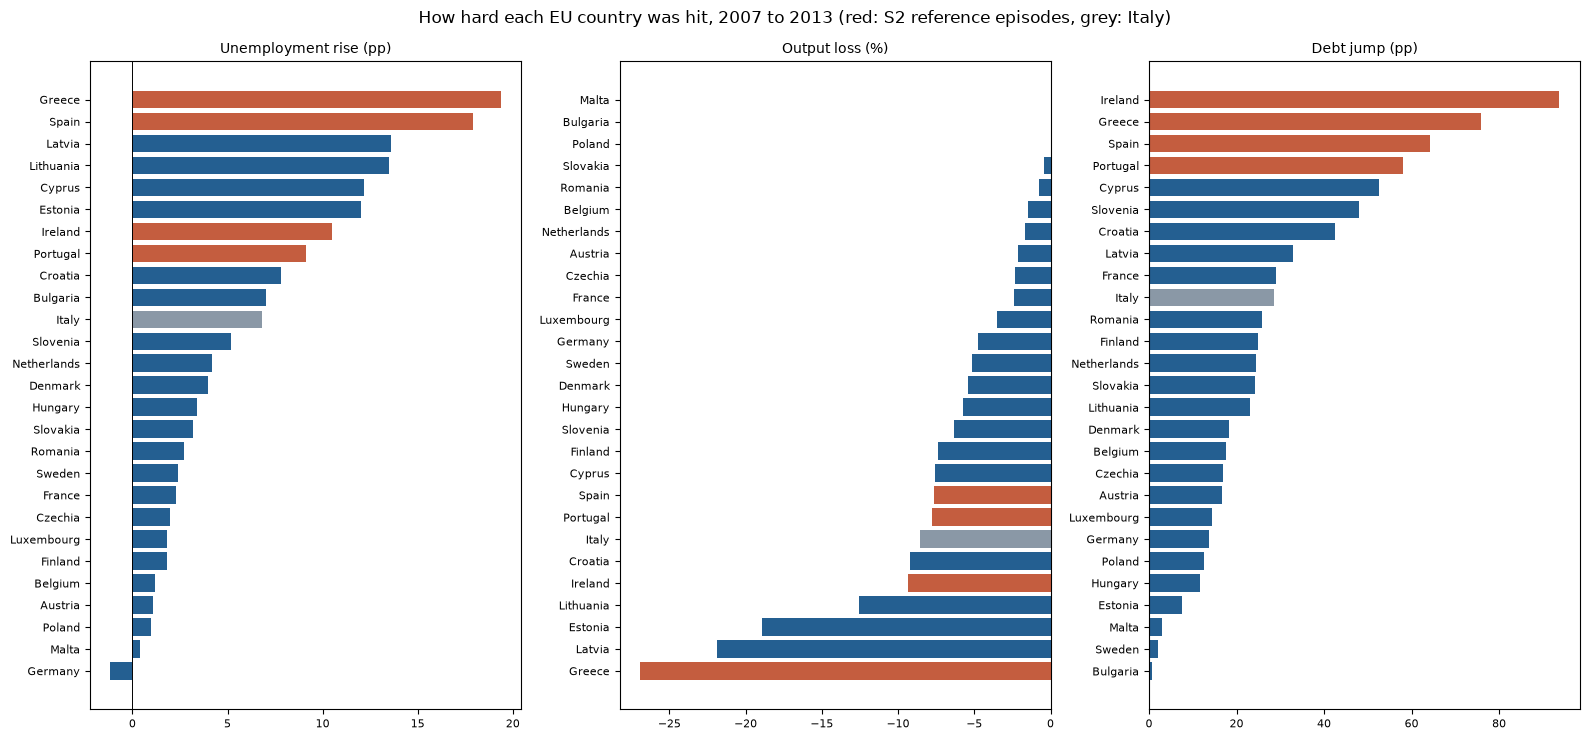

Country,Unemployment rise (pp),Output loss (%),Debt jump (pp),Peak year
Greece,19.400000,-26.927651,75.800000,2013
Spain,17.900000,-7.625477,64.300000,2013
Latvia,13.600000,-21.858328,32.900000,2010
Lithuania,13.500000,-12.584800,23.000000,2010
Cyprus,12.200000,-7.608787,52.600000,2014
Estonia,12.000000,-18.955400,7.500000,2010
Ireland,10.500000,-9.370500,93.800000,2012
Portugal,9.100000,-7.752845,58.100000,2013
Croatia,7.800000,-9.243071,42.400000,2013
Bulgaria,7.000000,0.000000,0.700000,2013


In [3]:
piv = lambda col: macro[macro.geo.isin(EU27)].pivot(index='year', columns='geo', values=col)
unemp, growth, debt = piv('une_rt_a_unemployment'), piv('nama_10_gdp_real_growth'), piv('gov_10dd_edpt1_debt_gdp')

rows = []
for g in EU27:
    u, gr, d = unemp[g], growth[g], debt[g]
    index = (1 + gr.loc[2008:2014] / 100).cumprod() * 100
    rows.append({'code': g, 'Country': NAME[g],
                 'Unemployment rise (pp)': u.loc[2008:2014].max() - u.loc[2007] if pd.notna(u.loc[2007]) else np.nan,
                 'Output loss (%)': min(index.min() - 100, 0) if gr.loc[2008:2014].notna().all() else np.nan,
                 'Debt jump (pp)': d.loc[2013] - d.loc[2007] if pd.notna(d.loc[2007]) and pd.notna(d.loc[2013]) else np.nan,
                 'Peak year': int(u.loc[2008:2014].idxmax()) if u.loc[2008:2014].notna().any() else np.nan})
sev = pd.DataFrame(rows).set_index('code')

fig, axes = plt.subplots(1, 3, figsize=(16, 7.5), sharey=False)
for ax, col in zip(axes, ['Unemployment rise (pp)', 'Output loss (%)', 'Debt jump (pp)']):
    d = sev[col].dropna().sort_values()
    colors = [RED if c in REFERENCE else GREY if c == 'IT' else BLUE for c in d.index]
    ax.barh([NAME[c] for c in d.index], d.values, color=colors)
    ax.axvline(0, color='black', lw=0.7)
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle('How hard each EU country was hit, 2007 to 2013 (red: S2 reference episodes, grey: Italy)', fontsize=12)
plt.tight_layout()
plt.show()

top = sev.sort_values('Unemployment rise (pp)', ascending=False)[['Country', 'Unemployment rise (pp)', 'Output loss (%)', 'Debt jump (pp)', 'Peak year']]
top.head(10).style.format({'Peak year': '{:.0f}'}).hide(axis='index')

In [4]:
cols = ['Unemployment rise (pp)', 'Output loss (%)', 'Debt jump (pp)']
ref = sev.loc[REFERENCE, cols]
as_hard = {}
for c in cols:
    ok = sev[c].dropna()
    # larger is worse for unemployment and debt; output loss is negative, so smaller is worse
    mild = ref[c].max() if c == 'Output loss (%)' else ref[c].min()
    hit = ok[ok <= mild] if c == 'Output loss (%)' else ok[ok >= mild]
    as_hard[c] = [NAME[x] for x in hit.index if x not in REFERENCE]
print('Countries OTHER than the four reference episodes that were hit at least as hard as the mildest of them:')
for c, names in as_hard.items():
    print(f"  {c}: {len(names)} countries: {', '.join(names)}")
sev[cols].describe().loc[['count', 'min', '50%', 'max']].rename(index={'50%': 'median'}).T

Countries OTHER than the four reference episodes that were hit at least as hard as the mildest of them:
  Unemployment rise (pp): 4 countries: Cyprus, Estonia, Lithuania, Latvia
  Output loss (%): 5 countries: Estonia, Croatia, Italy, Lithuania, Latvia
  Debt jump (pp): 0 countries: 


,count,min,median,max
Unemployment rise (pp),27.0,-1.2,4.0,19.4
Output loss (%),27.0,-26.9,-5.4,0.0
Debt jump (pp),27.0,0.7,24.2,93.8


**What this shows.** The four reference episodes are among the hardest hit, but **they are not alone**: the list above names the other countries hit at least as hard on each measure. Treating S2 as four cases throws away most of the variation. Severity is a **continuous** measure across many countries.

## 4. Is there a signal worth chasing? A first look, not a test

A quick look at whether trust in parliament fell more where unemployment rose more. **Two severity measures were chosen in advance from the literature** (unemployment rise, output loss), so this is two comparisons, not a search. It is exploratory and it is **not** the pre-specified test.

*Trust before* is the average of the Eurobarometer waves starting in 2006 and 2007; *trust after* is the average of the waves starting in 2012 and 2013.

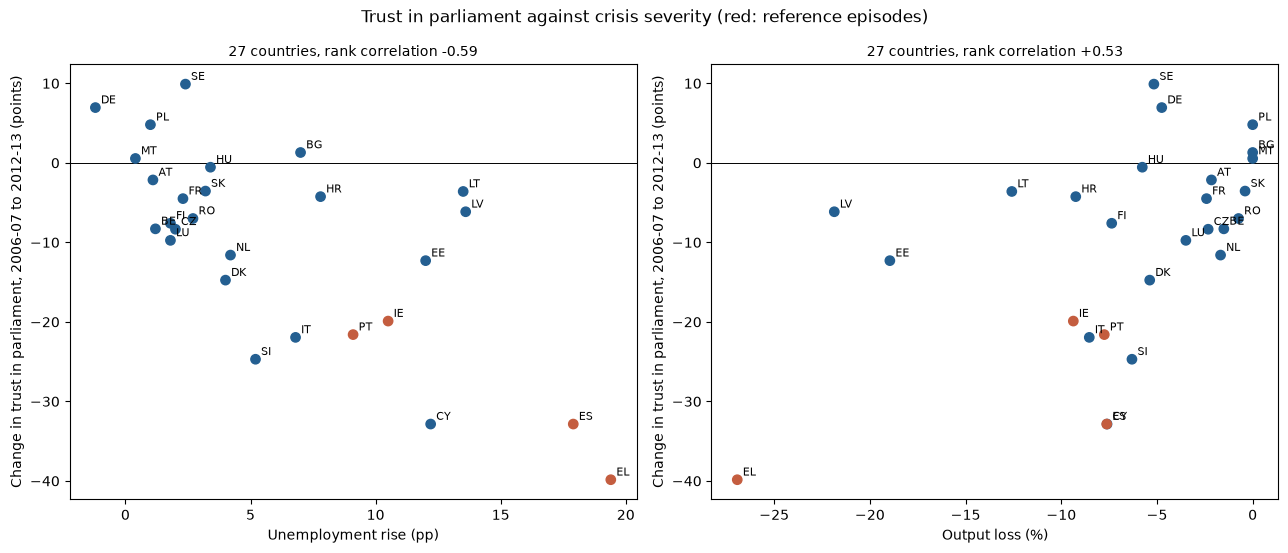

,Countries,Rank correlation,Chance,Without one country (range)
Severity measure,,,,
Unemployment rise (pp),27,-0.59,0.0008,-0.65 to -0.54
Output loss (%),27,+0.53,0.0044,+0.48 to +0.59


In [5]:
par = eb[eb.institution == 'National parliament']
def avg(years, code):
    d = par[(par.country_code == code) & par.start.dt.year.isin(years)]
    return d.trust.mean() if len(d) else np.nan
sev['Trust before'] = [avg([2006, 2007], c) for c in sev.index]
sev['Trust after'] = [avg([2012, 2013], c) for c in sev.index]
sev['Trust change'] = sev['Trust after'] - sev['Trust before']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
rng = np.random.default_rng(0)
summary = []
for ax, col in zip(axes, ['Unemployment rise (pp)', 'Output loss (%)']):
    d = sev[[col, 'Trust change']].dropna()
    ax.axhline(0, color='black', lw=0.7)
    ax.scatter(d[col], d['Trust change'], s=45, color=[RED if c in REFERENCE else BLUE for c in d.index], zorder=3)
    for c, r in d.iterrows():
        ax.annotate(c, (r[col], r['Trust change']), textcoords='offset points', xytext=(4, 3), fontsize=8)
    rx, ry = d[col].rank().values, d['Trust change'].rank().values
    r = np.corrcoef(rx, ry)[0, 1]
    perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(10000)])
    p = (np.abs(perm) >= abs(r)).mean()
    loo = [d.drop(c)[col].rank().corr(d.drop(c)['Trust change'].rank()) for c in d.index]
    summary.append({'Severity measure': col, 'Countries': len(d), 'Rank correlation': r, 'Chance': p,
                    'Without one country (range)': f"{min(loo):+.2f} to {max(loo):+.2f}"})
    ax.set_xlabel(col)
    ax.set_ylabel('Change in trust in parliament, 2006-07 to 2012-13 (points)')
    ax.set_title(f"{len(d)} countries, rank correlation {r:+.2f}", fontsize=10)
fig.suptitle('Trust in parliament against crisis severity (red: reference episodes)', fontsize=12)
plt.tight_layout()
plt.show()
pd.DataFrame(summary).set_index('Severity measure').style.format({'Rank correlation': '{:+.2f}', 'Chance': '{:.4f}', 'Countries': '{:.0f}'})

**How to read it.** Output loss is negative when output fell, so a positive correlation there means a bigger loss goes with a bigger fall in trust. With about 27 countries, a rank correlation beyond roughly **±0.39** stands out from chance at the 5% level (compare 0.71 for 8 cases in S1). If the relationship is as strong as it looks, the S2 design has real power that S1 lacked. This is only a first look: it does not control for anything, it uses one pair of dates, and it is two comparisons we chose ourselves.

## 5. What data we have, country by country

For each EU country: Eurobarometer waves in the crisis window (2007 to 2015), parliamentary elections (2008 to 2015), ESS rounds covering the crisis (rounds 4 to 7, 2008 to 2015), and complete Eurostat years.

In [6]:
from zipfile import ZipFile
with ZipFile(ROOT / 'data/raw/ppeg_2025v1/ppeg_parl_2025v1.zip') as archive:
    ppeg = pd.read_csv(archive.open('ppeg_parl_2025v1.csv'), usecols=['iso3c', 'edate'], low_memory=False).drop_duplicates()
ppeg['edate'] = pd.to_datetime(ppeg.edate)
ess = pd.read_csv(ROOT / 'data/processed/ess_country_round_summary.csv') if (ROOT / 'data/processed/ess_country_round_summary.csv').exists() else None

cov = []
for c in EU27:
    w = par[(par.country_code == c) & par.start.dt.year.between(2007, 2015)].wave.nunique()
    e = int(ppeg[(ppeg.iso3c == EB_TO_ISO3[c]) & ppeg.edate.dt.year.between(2008, 2015)].shape[0])
    s = int(ess[(ess.iso3 == EB_TO_ISO3[c]) & ess.essround.between(4, 7)].shape[0]) if ess is not None else np.nan
    full = int(macro[(macro.geo == c) & macro.year.between(2007, 2014)][['nama_10_gdp_real_growth', 'une_rt_a_unemployment', 'gov_10dd_edpt1_debt_gdp']].notna().all(axis=1).sum())
    cov.append({'Country': NAME[c], 'Trust waves 2007-15': w, 'Elections 2008-15': e, 'ESS rounds 4-7': s, 'Eurostat years 2007-14 (of 8)': full})
coverage = pd.DataFrame(cov).set_index('Country')
print(f"Country-waves of trust data in the window: {int(coverage['Trust waves 2007-15'].sum())}; elections: {int(coverage['Elections 2008-15'].sum())}; countries with fewer than 15 trust waves: {', '.join(coverage[coverage['Trust waves 2007-15'] < 15].index)}.")
coverage.style.format('{:.0f}')

Country-waves of trust data in the window: 540; elections: 59; countries with fewer than 15 trust waves: .


,Trust waves 2007-15,Elections 2008-15,ESS rounds 4-7,Eurostat years 2007-14 (of 8)
Country,,,,
Austria,20,2,1,8
Belgium,20,2,4,8
Bulgaria,20,3,3,8
Cyprus,20,1,3,8
Czechia,20,2,4,8
Germany,20,2,4,8
Denmark,20,2,4,8
Estonia,20,2,4,8
Greece,20,5,2,8


## 5b. The newly downloaded series

`src/prepare_s2_sources.py` decodes the Eurostat and World Bank files into one table per country and year. The first table counts, for each series, how many of the 27 countries have every year from 2007 to 2014. The second is the bailout-loan file summarised by country and facility.

In [7]:
inputs = pd.read_csv(ROOT / 'data/processed/s2_country_year_inputs.csv')
crisis = inputs[inputs.year.between(2007, 2014)]
labels = {'gdp_real_meur': 'Real GDP level', 'gdp_per_head_real_eur': 'GDP per head', 'net_lending_pct_gdp': 'Deficit (net lending, % GDP)',
          'bond_yield_pct': '10-year bond yield', 'youth_unemployment_pct': 'Youth unemployment', 'house_price_index': 'House price index',
          'bank_npl_pct': 'Bank loans in trouble (%)', 'une_rt_a_unemployment': 'Unemployment (already held)', 'gov_10dd_edpt1_debt_gdp': 'Debt (already held)'}
have = crisis.groupby('geo')[list(labels)].count().eq(8)
table = pd.DataFrame({'Countries complete 2007-2014 (of 27)': have.sum(),
                      'Missing': [', '.join(sorted(have.index[~have[c]])) for c in have.columns]}).rename(index=labels)
table['Missing'] = table['Missing'].where(table['Missing'].str.len() < 60, 'many (' + (27 - table['Countries complete 2007-2014 (of 27)']).astype(str) + ' countries)')
display(table.style.format({'Countries complete 2007-2014 (of 27)': '{:.0f}'}))
bail = pd.read_csv(ROOT / 'data/processed/s2_bailout_country.csv')
bail = bail[bail.had_programme == 1].assign(Country=lambda d: d.geo.map(NAME))
bail[['Country', 'first_disbursement', 'last_disbursement', 'esm_efsf_bn', 'ec_imf_bn', 'total_disbursed_bn', 'total_pct_gdp_2012']].rename(
    columns={'first_disbursement': 'First money', 'last_disbursement': 'Last money', 'esm_efsf_bn': 'ESM/EFSF (bn EUR)',
             'ec_imf_bn': 'EU and IMF (bn EUR)', 'total_disbursed_bn': 'Total (bn EUR)', 'total_pct_gdp_2012': 'Total, % of 2012 GDP'}
).sort_values('First money').style.hide(axis='index').format({'ESM/EFSF (bn EUR)': '{:.1f}', 'EU and IMF (bn EUR)': '{:.1f}', 'Total (bn EUR)': '{:.1f}', 'Total, % of 2012 GDP': '{:.0f}'})

,Countries complete 2007-2014 (of 27),Missing
Real GDP level,27,
GDP per head,27,
"Deficit (net lending, % GDP)",27,
10-year bond yield,26,EE
Youth unemployment,27,
House price index,19,"AT, CZ, EL, HR, IT, PL, PT, RO"
Bank loans in trouble (%),9,many (18 countries)
Unemployment (already held),27,
Debt (already held),27,


Country,First money,Last money,ESM/EFSF (bn EUR),EU and IMF (bn EUR),Total (bn EUR),"Total, % of 2012 GDP"
Hungary,2008-11-06,2010-10-05,0.0,14.2,14.2,14
Latvia,2008-12-23,2011-12-22,0.0,4.0,4.0,19
Romania,2009-05-04,2011-06-22,0.0,17.0,17.0,12
Greece,2010-05-01,2018-08-06,203.8,92.0,295.7,159
Ireland,2010-12-16,2014-03-25,18.4,45.0,63.4,36
Portugal,2011-05-20,2014-11-12,27.3,50.8,78.1,46
Spain,2012-12-11,2013-02-05,41.3,0.0,41.3,4
Cyprus,2013-05-13,2016-03-06,6.3,0.9,7.2,37


**What this shows.** Output, deficit, youth unemployment and income are complete for all countries and bond yields for 26 (no Estonia). House prices (19 of 27) and bank loans in trouble (9 of 27) have gaps, so they should be backups, not the main measure. The programme table now combines your ESM/EFSF file with the European Commission and IMF records (`data/reference/s2_bailout_programmes_ec_imf.csv`, one row per lender with its source link). **Eight countries had a programme**, not five: Latvia, Hungary and Romania (2008 to 2011, not in the euro) were hit early and are in. Spain took only the ESM bank loan. Poland held IMF precautionary lines and Romania held precautionary EU lines, but none was drawn, so they do not count. Three cautions: (1) the totals are cumulative to 2018, so Greece's 159% of GDP includes the 2015 to 2018 programme; (2) IMF amounts are converted from SDR at about 1.1 to 1.2 euro per SDR, and IMF dates are the arrangement dates, not the draw dates; (3) the UK, Swedish and Danish loans to Ireland (4.8 bn) and the Nordic and other loans to Latvia (2.7 bn) are agreed amounts I could not find as paid, so they are left out.

In [8]:
# Cleaner severity measures from the new series, compared with the ones built from growth rates
g = inputs[inputs.geo.isin(EU27)].pivot(index='year', columns='geo', values='gdp_real_meur')
level_loss = (g.loc[2008:2014].min() / g.loc[2007] - 1) * 100
level_loss = level_loss.clip(upper=0)
yields = inputs.pivot(index='year', columns='geo', values='bond_yield_pct')
deficit = inputs.pivot(index='year', columns='geo', values='net_lending_pct_gdp')
new = pd.DataFrame({'Output loss from levels (%)': level_loss,
                    'Peak bond yield 2008-14 (%)': yields.loc[2008:2014].max(),
                    'Spread over Germany at peak (pp)': (yields.loc[2008:2014].sub(yields.loc[2008:2014, 'DE'], axis=0)).max(),
                    'Worst deficit 2008-14 (% GDP)': deficit.loc[2008:2014].min()})
check = pd.concat([sev['Output loss (%)'], new['Output loss from levels (%)']], axis=1).dropna()
print(f"Output loss from growth rates vs from GDP levels: rank correlation {check.iloc[:, 0].rank().corr(check.iloc[:, 1].rank()):.2f} over {len(check)} countries.")
new.loc[REFERENCE + ['IT']].rename(index=NAME).style.format('{:.1f}')

Output loss from growth rates vs from GDP levels: rank correlation 1.00 over 27 countries.


,Output loss from levels (%),Peak bond yield 2008-14 (%),Spread over Germany at peak (pp),Worst deficit 2008-14 (% GDP)
geo,,,,
Spain,-7.7,5.8,4.3,-11.5
Greece,-27.0,22.5,21.0,-15.4
Portugal,-7.7,10.6,9.1,-11.4
Ireland,-9.4,9.6,7.0,-32.2
Italy,-8.6,5.5,4.0,-5.1


## 5c. Observations with what we have

Everything below uses the 27 countries and the data now in the repo. **Nothing here is the final test.** Seven severity measures against six outcomes is 42 comparisons, so a few will look good by luck. To keep that honest: the one measure and the outcomes the Scope Review points to (unemployment rise; trust in parliament; radical vote) are the *main* comparisons, and the Bonferroni line below counts all 42.

*Change in trust* is the average of the Eurobarometer waves starting in 2012 and 2013 minus the average of those starting in 2006 and 2007 (the "late" version uses 2014 and 2015). *Satisfaction with democracy* is the ESS mean in round 6 minus round 3 (only countries in both). *Radical vote* is the far-right plus far-left share at the last election up to 2007, and the last election between January 2011 and June 2015.

In [9]:
from radical_links import election_shares
with ZipFile(ROOT / 'data/raw/ppeg_2025v1/ppeg_parl_2025v1.zip') as archive:
    ppeg_full = pd.read_csv(archive.open('ppeg_parl_2025v1.csv'), low_memory=False)
links = pd.read_csv(ROOT / 'outputs/data_audit/popu_ppeg_links.csv').fillna({'note': ''})
shares = election_shares(ppeg_full, links).assign(edate=lambda d: pd.to_datetime(d.edate))

P = lambda col, src=inputs: src[src.geo.isin(EU27)].pivot(index='year', columns='geo', values=col)
yields, deficit, youth, gdp_lv, gdp_head = P('bond_yield_pct'), P('net_lending_pct_gdp'), P('youth_unemployment_pct'), P('gdp_real_meur'), P('gdp_per_head_real_eur')
bail_c = pd.read_csv(ROOT / 'data/processed/s2_bailout_country.csv').set_index('geo')

obs = pd.DataFrame(index=EU27)
obs['Unemployment rise'] = sev['Unemployment rise (pp)']
obs['Output loss'] = (gdp_lv.loc[2008:2014].min() / gdp_lv.loc[2007] - 1).mul(100).clip(upper=0)
obs['Debt jump'] = sev['Debt jump (pp)']
obs['Bond spread peak'] = yields.loc[2008:2014].sub(yields.loc[2008:2014, 'DE'], axis=0).max()
obs['Worst deficit'] = -deficit.loc[2008:2014].min()
obs['Youth unemployment rise'] = youth.loc[2008:2014].max() - youth.loc[2007]
obs['Bailout size (% GDP)'] = [bail_c.total_pct_gdp_2012.get(g, 0.0) for g in obs.index]
SEVERITY = list(obs.columns)
obs['bailout'] = [int(bail_c.had_programme.get(g, 0)) for g in obs.index]

def trust(inst, years, code):
    d = eb[(eb.institution == inst) & (eb.country_code == code) & eb.start.dt.year.isin(years)]
    return d.trust.mean() if len(d) else np.nan
for inst, key in [('National parliament', 'parliament'), ('National government', 'government'), ('Political parties', 'parties')]:
    before = pd.Series({c: trust(inst, [2006, 2007], c) for c in EU27})
    obs[f'Trust in {key}'] = pd.Series({c: trust(inst, [2012, 2013], c) for c in EU27}) - before
    if key == 'parliament':
        obs['trust_before'] = before
        obs['Trust in parliament, late'] = pd.Series({c: trust(inst, [2014, 2015], c) for c in EU27}) - before
ess_p = ess.pivot(index='iso3', columns='essround', values='stfdem_mean')
ess_p.index = [ISO3_TO_EB.get(i, i) for i in ess_p.index]
obs['Satisfaction with democracy'] = (ess_p[6] - ess_p[3]).reindex(EU27)
before_after = {}
for c in EU27:
    d = shares[shares.iso3 == EB_TO_ISO3[c]].sort_values('edate')
    b, a = d[d.edate <= '2007-12-31'], d[(d.edate >= '2011-01-01') & (d.edate <= '2015-06-30')]
    before_after[c] = (b.radical_pct.iloc[-1], a.radical_pct.iloc[-1]) if len(b) and len(a) else (np.nan, np.nan)
obs['radical_before'] = pd.Series({c: v[0] for c, v in before_after.items()})
obs['Radical vote'] = pd.Series({c: v[1] - v[0] for c, v in before_after.items()})
obs['gdp_head_2007'] = gdp_head.loc[2007]
obs['euro_2008'] = [int(c in ['AT', 'BE', 'CY', 'DE', 'EL', 'ES', 'FI', 'FR', 'IE', 'IT', 'LU', 'MT', 'NL', 'PT', 'SI', 'SK']) for c in EU27]
obs['east'] = [int(c in ['BG', 'CZ', 'EE', 'HR', 'HU', 'LT', 'LV', 'PL', 'RO', 'SI', 'SK']) for c in EU27]
OUTCOMES = ['Trust in parliament', 'Trust in government', 'Trust in parties', 'Trust in parliament, late', 'Satisfaction with democracy', 'Radical vote']

rng = np.random.default_rng(1)
def rank_test(x, y, n=10000):
    d = pd.concat([x, y], axis=1).dropna()
    rx, ry = d.iloc[:, 0].rank().values, d.iloc[:, 1].rank().values
    r = np.corrcoef(rx, ry)[0, 1]
    perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(n)])
    loo = [d.drop(i).iloc[:, 0].rank().corr(d.drop(i).iloc[:, 1].rank()) for i in d.index]
    return len(d), r, max((np.abs(perm) >= abs(r)).mean(), 1 / n), min(loo), max(loo)

grid = pd.DataFrame([dict(zip(['n', 'rho', 'p', 'lo', 'hi'], rank_test(obs[s], obs[o])), severity=s, outcome=o) for s in SEVERITY for o in OUTCOMES])
BONF = 0.05 / len(grid)
# Expected sign: harder hit -> bigger fall in trust or satisfaction (negative, except output loss which is negative when worse -> positive), and a bigger rise in radical vote (the reverse)
expected = np.where(grid.outcome.eq('Radical vote'), 1, -1) * np.where(grid.severity.eq('Output loss'), -1, 1)
grid['as_expected'] = np.sign(grid.rho) == expected
main_p = grid[(grid.severity == 'Unemployment rise') & grid.outcome.isin(['Trust in parliament', 'Radical vote'])].set_index('outcome').p
print(f'{len(grid)} comparisons. Bonferroni line: p below {BONF:.4f}; {int((grid.p < BONF).sum())} pass it.')
print(f'Sign as expected: {int(grid.as_expected.sum())} of {len(grid)} (trust and satisfaction columns: {int(grid[grid.outcome != "Radical vote"].as_expected.sum())} of {int((grid.outcome != "Radical vote").sum())}; radical vote: {int(grid[grid.outcome == "Radical vote"].as_expected.sum())} of {int((grid.outcome == "Radical vote").sum())}).')
print(f'Main comparisons (unemployment rise; two main outcomes, line p < 0.025): trust in parliament p = {main_p["Trust in parliament"]:.4f}, radical vote p = {main_p["Radical vote"]:.3f}.')
show = grid.pivot(index='severity', columns='outcome', values='rho').loc[SEVERITY, OUTCOMES]
flag = grid.pivot(index='severity', columns='outcome', values='p').loc[SEVERITY, OUTCOMES] < BONF
print('Rank correlation between severity (rows) and the change in each outcome (columns). * = passes the Bonferroni line.')
show.round(2).astype(str).where(~flag, show.round(2).astype(str) + ' *').rename_axis(None)

42 comparisons. Bonferroni line: p below 0.0012; 6 pass it.
Sign as expected: 36 of 42 (trust and satisfaction columns: 35 of 35; radical vote: 1 of 7).
Main comparisons (unemployment rise; two main outcomes, line p < 0.025): trust in parliament p = 0.0013, radical vote p = 0.579.
Rank correlation between severity (rows) and the change in each outcome (columns). * = passes the Bonferroni line.


outcome,Trust in parliament,Trust in government,Trust in parties,"Trust in parliament, late",Satisfaction with democracy,Radical vote
Unemployment rise,-0.59,-0.58,-0.58,-0.46,-0.75 *,-0.11
Output loss,0.53,0.53,0.53,0.38,0.63,-0.09
Debt jump,-0.73 *,-0.7 *,-0.7 *,-0.76 *,-0.75 *,-0.18
Bond spread peak,-0.31,-0.31,-0.32,-0.25,-0.4,-0.32
Worst deficit,-0.43,-0.46,-0.4,-0.47,-0.58,-0.32
Youth unemployment rise,-0.54,-0.52,-0.51,-0.43,-0.67,-0.25
Bailout size (% GDP),-0.45,-0.48,-0.47,-0.4,-0.43,-0.11


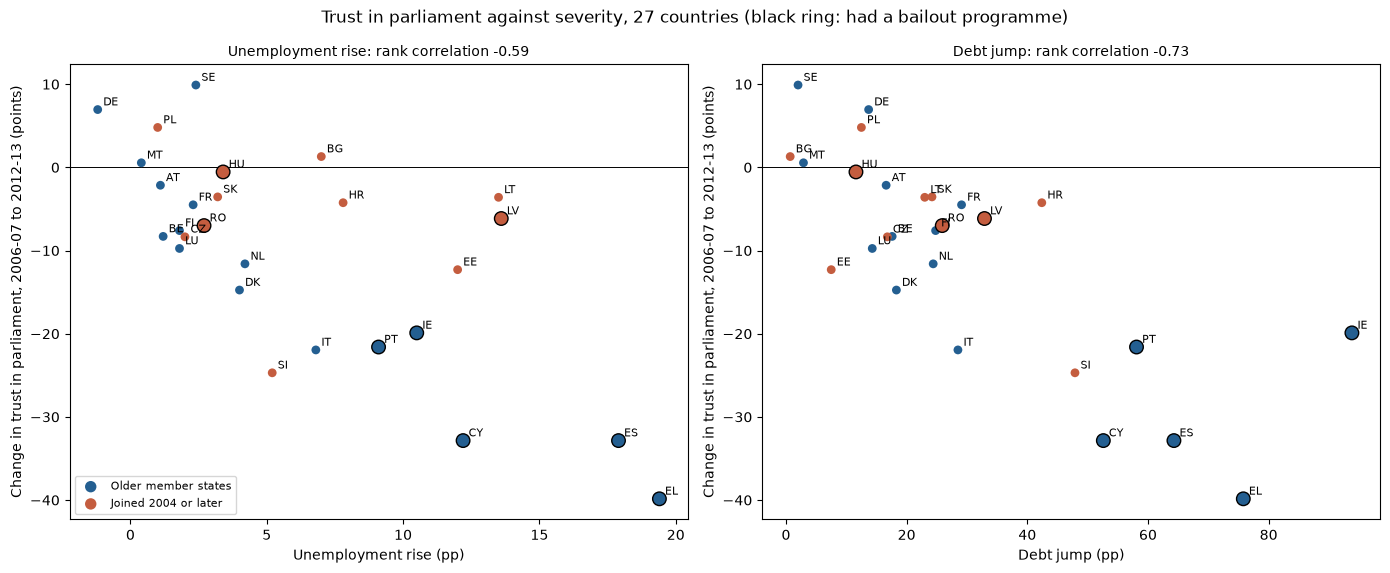

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
for ax, s in zip(axes, ['Unemployment rise', 'Debt jump']):
    d = obs[[s, 'Trust in parliament', 'bailout', 'east']].dropna()
    for east, color, label in [(0, BLUE, 'Older member states'), (1, RED, 'Joined 2004 or later')]:
        m = d[d.east == east]
        ax.scatter(m[s], m['Trust in parliament'], s=np.where(m.bailout == 1, 95, 40), color=color, edgecolor=np.where(m.bailout == 1, 'black', 'none'), label=label, zorder=3)
    for c, r in d.iterrows():
        ax.annotate(c, (r[s], r['Trust in parliament']), textcoords='offset points', xytext=(4, 3), fontsize=8)
    ax.axhline(0, color='black', lw=0.7)
    ax.set_xlabel(s + (' (pp)'))
    ax.set_ylabel('Change in trust in parliament, 2006-07 to 2012-13 (points)')
    rho = grid[(grid.severity == s) & (grid.outcome == 'Trust in parliament')].rho.iloc[0]
    ax.set_title(f'{s}: rank correlation {rho:+.2f}', fontsize=10)
axes[0].legend(fontsize=8, loc='lower left')
fig.suptitle('Trust in parliament against severity, 27 countries (black ring: had a bailout programme)', fontsize=12)
plt.tight_layout()
plt.show()

In [11]:
def zs(x): return (x - x.mean()) / x.std()
def std_coef(d, y, xs):
    d = d[[y] + xs].dropna()
    X = np.column_stack([np.ones(len(d))] + [zs(d[x]).values for x in xs])
    return np.linalg.lstsq(X, zs(d[y]).values, rcond=None)[0][1], d

rows = []
for sev_name in ['Unemployment rise', 'Debt jump']:
    for y, base in [('Trust in parliament', 'trust_before'), ('Radical vote', 'radical_before')]:
        for label, ctrl in [('none', []), ('starting level', [base]), ('starting level, income, euro', [base, 'gdp_head_2007', 'euro_2008'])]:
            xs = [sev_name] + ctrl
            b, d = std_coef(obs, y, xs)
            boot = []
            for _ in range(3000):
                sample = d.sample(len(d), replace=True, random_state=int(rng.integers(1e9)))
                try:
                    boot.append(std_coef(sample, y, xs)[0])
                except Exception:
                    pass
            lo, hi = np.percentile(boot, [2.5, 97.5])
            rows.append({'Severity': sev_name, 'Outcome': y, 'Controls': label, 'Effect (std.)': b, 'Low': lo, 'High': hi, 'Countries': len(d)})
adj = pd.DataFrame(rows)
adj['95% interval'] = adj.apply(lambda r: f"{r.Low:+.2f} to {r.High:+.2f}", axis=1)
print('Standardised effect of severity on the change in the outcome, with and without controls (95% bootstrap interval over countries).')
adj[['Severity', 'Outcome', 'Controls', 'Effect (std.)', '95% interval', 'Countries']].style.hide(axis='index').format({'Effect (std.)': '{:+.2f}'})

Standardised effect of severity on the change in the outcome, with and without controls (95% bootstrap interval over countries).


Severity,Outcome,Controls,Effect (std.),95% interval,Countries
Unemployment rise,Trust in parliament,none,-0.70,-0.88 to -0.35,27
Unemployment rise,Trust in parliament,starting level,-0.74,-0.87 to -0.48,27
Unemployment rise,Trust in parliament,"starting level, income, euro",-0.72,-0.90 to -0.48,27
Unemployment rise,Radical vote,none,-0.10,-0.42 to +0.24,26
Unemployment rise,Radical vote,starting level,-0.11,-0.47 to +0.26,26
Unemployment rise,Radical vote,"starting level, income, euro",+0.07,-0.32 to +0.42,26
Debt jump,Trust in parliament,none,-0.78,-0.91 to -0.61,27
Debt jump,Trust in parliament,starting level,-0.77,-0.91 to -0.62,27
Debt jump,Trust in parliament,"starting level, income, euro",-0.74,-0.99 to -0.54,27
Debt jump,Radical vote,none,-0.10,-0.40 to +0.19,26


In [12]:
rows = []
for name, d in [('Older member states', obs[obs.east == 0]), ('Joined 2004 or later', obs[obs.east == 1])]:
    rows.append({'Group': name, 'Countries': len(d), 'Mean trust change': d['Trust in parliament'].mean(),
                 'Unemployment rise vs trust': d['Unemployment rise'].rank().corr(d['Trust in parliament'].rank()),
                 'Debt jump vs trust': d['Debt jump'].rank().corr(d['Trust in parliament'].rank())})
for name, d in [('Had a bailout programme', obs[obs.bailout == 1]), ('No programme', obs[obs.bailout == 0])]:
    rows.append({'Group': name, 'Countries': len(d), 'Mean trust change': d['Trust in parliament'].mean(), 'Unemployment rise vs trust': np.nan, 'Debt jump vs trust': np.nan})
pd.DataFrame(rows).style.hide(axis='index').format({'Mean trust change': '{:.1f}', 'Unemployment rise vs trust': '{:+.2f}', 'Debt jump vs trust': '{:+.2f}', 'Countries': '{:.0f}'}, na_rep='')

Group,Countries,Mean trust change,Unemployment rise vs trust,Debt jump vs trust
Older member states,16,-13.1,-0.88,-0.83
Joined 2004 or later,11,-5.8,-0.21,-0.45
Had a bailout programme,8,-20.1,,
No programme,19,-6.0,,


**What the data say** (descriptive, 27 countries, one pair of dates):

1. **Trust in parliament fell more where the crisis hit harder.** Unemployment rise and the change in trust have a rank correlation of about −0.6, and the pattern holds when any single country is removed (about −0.54 to −0.65), when the starting level of trust, income and euro membership are held fixed, and for trust in government and in parties. Satisfaction with democracy (17 countries) points the same way. For the main comparison (unemployment rise against trust in parliament) the result passes the correction for the two main outcomes. It does **not** pass the strict line for all 42 comparisons; the debt jump does, for trust in parliament, in government, in parties and in 2014–15, and unemployment rise does for satisfaction with democracy.
2. **Public debt jump is the strongest single measure** (about −0.73) and it is the one that still shows a gap in 2014–15, so trust had not come back. Debt is partly the bill for rescuing banks, so it mixes the cause (a financial shock) with the policy response. The bond-spread measure of sovereign stress is weaker (about −0.3 and not distinguishable from chance), and so is the output loss.
3. **Countries with a bailout programme lost about 20 points of trust on average, the others about 6.** Bailout size is related to the trust drop (about −0.45), a little less strongly than unemployment, so it adds little beyond what severity already says.
4. **It is mostly a story of the older member states.** Within the 16 older members the link between unemployment and trust is about −0.9; within the 11 countries that joined later it is about −0.2. Those countries started with low trust (little room to fall) and many had short or early shocks. A single EU-wide pattern would hide this.
5. **No detectable link with the radical vote.** The correlations are weak and the intervals include zero, whichever severity measure is used. The sign is in fact slightly opposite to the usual expectation (harder-hit countries show a smaller rise in radical vote), but it is not distinguishable from zero. This is not proof of no effect: the radical-vote measure is noisy and has known gaps (for example Italy's −13 comes from parties merging, and Finland, Poland and Lithuania show zero because their parties are not classed the same way throughout 2000 to 2025). It is also one election per country.
6. **How much to trust all this.** It is correlation across countries: it does not show the crisis caused the fall. Countries that were hit hard also differ in other ways, so the controls help but do not settle it. Eurobarometer has about 3 points of sampling noise per country. The Bonferroni count above is the honest measure of how many of the 42 comparisons stand up on their own.

## 6. Three ways to build S2

| | A. Reference episodes | B. One row per country | C. Country-by-wave panel |
| --- | --- | --- | --- |
| **Cases** | 4 to 5 countries | about 26 countries | about 500 country-waves, about 130 elections |
| **Severity** | The case is "hit" | One continuous number per country | A number that **changes over time** (unemployment this year) |
| **Question** | What happened in the hard cases? | Did more severely hit countries change more, 2007 to 2013? | How do trust and votes move as unemployment and output move, within each country? |
| **Power** | Almost none | Moderate | Highest, and can show the **path** (before, during, after) |
| **Risks** | The S1 problem again | One window; countries differ in many ways | Needs care with timing and with elections on their own calendar |
| **Fit to the Scope Review** | The deck's wording | A natural extension | Closest to a stress test: severity in, outcome out |

**Suggested design:** use **B as the main analysis** and **C as the check**, with A (the four reference episodes) shown as case studies inside them. All three use the same variables, so the choice does not change what has to be built.

## 7. What to freeze before building

These are proposals for the team. Writing them down now is what protects the analysis from the many-tests problem.

**Window.** Baseline 2006 to 2007 (before the crisis became visible). Follow-up: 2012 to 2013 (the crisis peak for most) and 2014 to 2015 (recovery). Stop before the 2015 migration surge.

**Main severity measure.** The rise in unemployment from 2007 to its peak. Backups, reported but not searched: output loss, debt jump, and bailout programme (yes or no).

**Main outcomes (3).** Trust in parliament; far-right plus far-left vote at the first election after 2008; the populist vote (once computed). Secondary: trust in government and parties, turnout, number of parties.

**Controls (4).** Trust before the crisis, euro membership, income level, and the radical vote before the crisis.

**Tests.** One rank correlation per outcome for the main severity measure; every other combination reported as exploratory. Correct for the number of outcomes. Re-run without each country in turn (Greece in particular). Allow for countries that resemble each other.

## 8. Data to add, and decisions for the team

**Done since the first version:** Eurostat bond yields, deficit, GDP levels, GDP per head, youth unemployment and house prices, the World Bank bank-loans-in-trouble series, the team's ESM/EFSF loan file, and the European Commission and IMF programme records are in `data/raw/` and decoded.

**Still to download or build:**

1. **Systemic banking crises:** the IMF database by Laeven and Valencia (start year, fiscal cost, output loss). Needs a manual download.
2. **Bailout programmes, the last gaps:** the amounts actually paid by the UK, Sweden and Denmark to Ireland, by the Nordic countries to Latvia, and the exact draw dates of IMF loans. Everything else is now in `data/reference/s2_bailout_programmes_ec_imf.csv`.
3. **Gaps in the new series:** an Estonian bond yield, house prices for 8 countries, a fuller bank-loans series (IMF Financial Soundness Indicators or ECB are options).
4. **Euro membership and EU accession years:** a short hand-made table.
5. **Populist vote:** PopuList's populist flag linked to PPEG, with the same checks as the radical vote.
6. **Satisfaction with democracy, twice a year:** not in the Eurobarometer volume we hold; it needs the per-wave Standard Eurobarometer files from GESIS (free registration). Trust in European institutions is already in the repo as raw tables (STD105 volume D, QA12.1 to QA12.4) and only needs processing. The Mannheim Trend File covers 1970 to 2002 only, so it does not help for the crisis.

**Decisions for the team:**

- Is S2 allowed to include **every EU country**, with the four reference episodes as case studies? (Recommended.)
- Which **severity measure is the main one**: unemployment rise, or a combined index?
- Are **euro membership** and **bailout programme** inputs or controls? A bailout is both a consequence of the crisis and a political event.
- Which **outcomes are primary**? The more we add, the stricter the bar for each.
- Do we keep **trust in European institutions** as an outcome? It is the natural euro-crisis outcome and the raw tables are already in the repo.

## Sources used for the variable choices

- Unemployment as the severity measure for trust and populism in the 2008 to 2013 crisis: Algan, Guriev, Papaioannou and Passari, [The European Trust Crisis and the Rise of Populism](https://www.brookings.edu/articles/the-european-trust-crisis-and-the-rise-of-populism) (Brookings Papers on Economic Activity, 2017). They report that rising unemployment goes with lower trust in national and European institutions and more votes for non-mainstream, especially populist, parties, strongest in Southern Europe.
- Far-right gains after financial crises, and the point that normal recessions do not show them: Funke, Schularick and Trebesch, [Going to Extremes](https://voxeu.org/article/political-aftermath-financial-crises-going-extremes) (European Economic Review, 2016): about 30% more far-right vote after a systemic banking crisis.
- Banking crises database: Laeven and Valencia, [IMF Working Paper 18/206](https://www.imf.org/en/publications/wp/issues/2016/12/31/systemic-banking-crises-a-new-database-22345) and its updates; country start years still to be read from the database itself.
- Trust and satisfaction with democracy falling most where the crisis hit hardest: several studies using Eurobarometer and ESS, for example Polavieja, [IMDEA working paper 2012-08](https://ideas.repec.org/p/imd/wpaper/wp2012-08.html). These sources were found by search and I have not read the full texts.